In [4]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import fetch_openml

In [5]:

# Import the MNIST dataset. this might be slow  
X,y = fetch_openml('mnist_784',
 return_X_y=True)

In [6]:
n_images = X.shape[0]

# Convert data to numpy image pixel-by-pixel representation
X_images = X.to_numpy().reshape(n_images, 28, 28)

# Flatten the data so that we can apply clustering
X_flat = X_images.reshape(n_images, 28 * 28)

In [7]:
print(X.shape, X_flat.shape, X_images.shape, y.shape)
X_images[0]

(70000, 784) (70000, 784) (70000, 28, 28) (70000,)


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

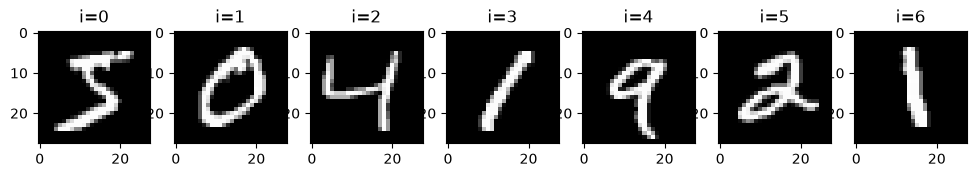

In [8]:
# plot the resulting images
plt.figure(figsize=(12, 12))
img_max = 7
for i in range(img_max):
    ax = plt.subplot(img_max, img_max, i + 1)
    plt.imshow(X_images[i,:], cmap=plt.cm.gray)
    ax.set_title(f"i={i}")
    

See if the elbow plot is useful. Is there an elbow at k = 10? This will be slow because it has to chug through a lot of images.

In [9]:
inertia = []
for k in range(7 , 14): # this is slow
    algorithm = (KMeans(n_clusters = k ,init='k-means++', n_init = 10 ,max_iter=100, 
                        tol=0.0001,  random_state= 111  , algorithm='elkan') )
    algorithm.fit(X_flat)
    inertia.append(algorithm.inertia_)

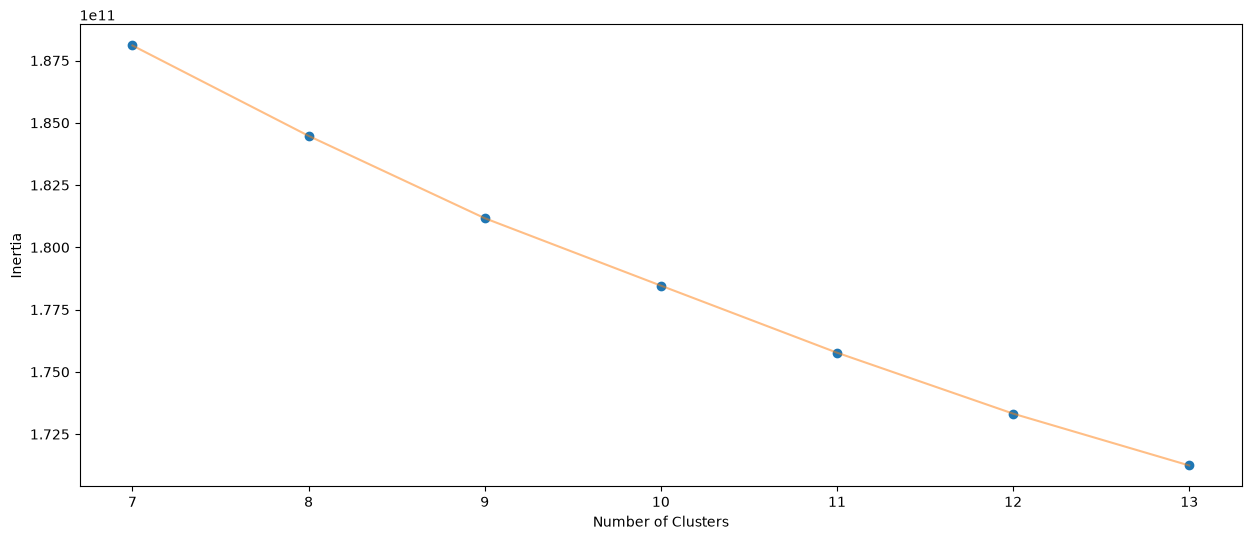

In [10]:
plt.figure(1 , figsize = (15 ,6))
plt.plot(np.arange(7 , 14) , inertia , 'o')
plt.plot(np.arange(7 , 14) , inertia , '-' , alpha = 0.5)
plt.xlabel('Number of Clusters') , plt.ylabel('Inertia')
plt.show()

Since k-means calculates the location of the centroid (which can be interpreted as the 'average' image), we can plot these centroids as images.

### Plotting Code
We are going to be needing plotting code a lot, so we'll encapsulate into a function.




In [11]:
def cluster_and_plot(X_flat, n_clusters):
    algorithm = (KMeans(n_clusters = n_clusters ,init='k-means++', n_init = 10 ,max_iter=100, 
                            tol=0.0001,  random_state= 111  , algorithm='elkan') )
    algorithm.fit(X_flat)
    labels = algorithm.labels_
    centroids = algorithm.cluster_centers_

    fig, axes = plt.subplots(1, n_clusters)
    n_clusters = len(np.unique(labels))

    for c_i in range(n_clusters):
        # get center for cluster c_i and reshape it for plotting
        image = centroids[c_i].reshape(28,28)

        # plot the cluster centers
        axes[c_i].imshow(image, cmap='grey')
        axes[c_i].set_yticks([])
        axes[c_i].set_xticks([])
    return labels

# labels - the output of the clustering algorithm
# X_images - the original images in 28x28 pixel format
# n_clusters - the number of clusters in the clustering algorithm, such as 10 (the true value) or 13 (if you are being experimental)

def plot_images(labels, X_images, n_clusters):
    image_cluster = [[] for _ in range(n_clusters)] 
    # Collect all images that belong to each cluster. j ranges over the cluster labels (0-9) 
    img_max = 300
    for j in range(n_clusters):
        for i in range(img_max):
            if labels[i] == j:  # Only collect images that belong to the current cluster
                image_cluster[j].append(X_images[i, :])
            if len(image_cluster[j]) >= 13:  # Limit to 10 images per cluster
                break
            
    for n in range(len(image_cluster)):
        k = len(image_cluster[n])
        fig, axes = plt.subplots(1, k, figsize=(1 * k, 1), squeeze=False)
        for i, ax in enumerate(axes[0]):
            ax.imshow(image_cluster[n][i], cmap=plt.cm.gray)
            ax.set_title(f"Cluster{n}")
            ax.axis("off")
        plt.show()

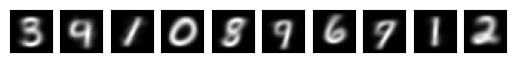

In [12]:
n_clusters = 10
labels = cluster_and_plot(X_flat , n_clusters) 

Looking at the averages, we can see what the numbers are supposed to be, mostly. Unfortunately, the fours, nines and sevens look hard to distinguish, and there's no 5 - it looks like it got added into the 8.


We can get a sense of what happened by looking at individual images.

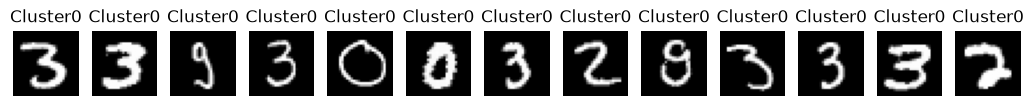

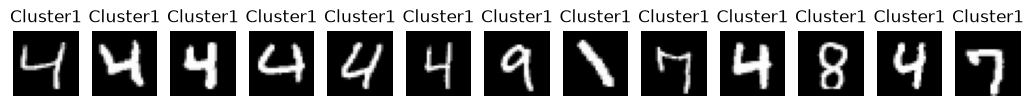

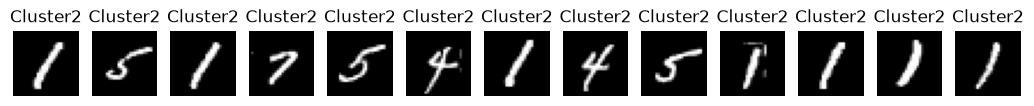

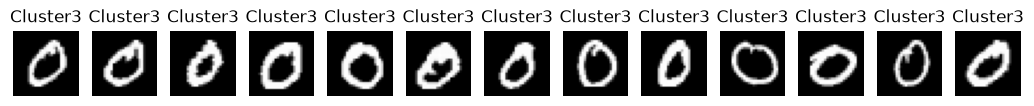

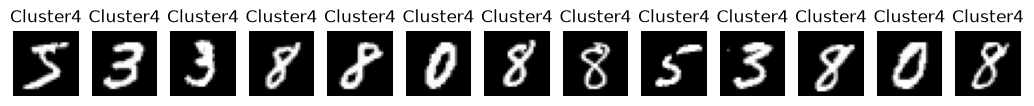

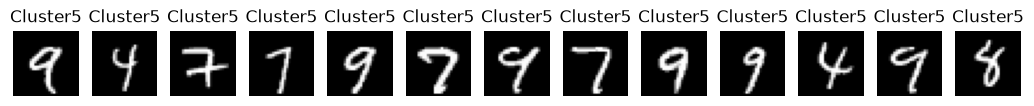

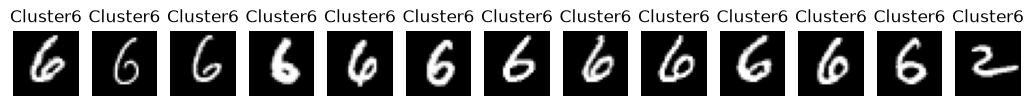

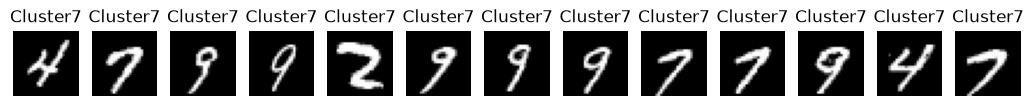

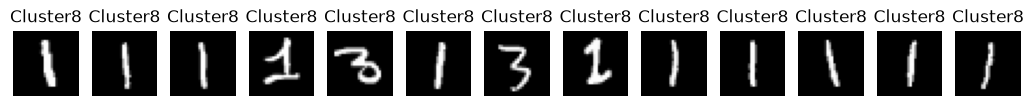

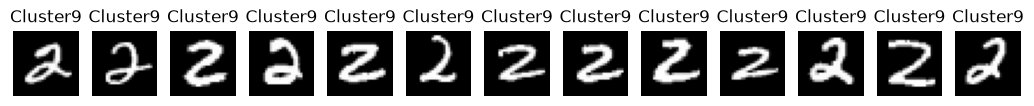

In [13]:
plot_images(labels, X_images, 10)

Looking at the images, we can try to assign numerical labels to each cluster. In some cases, this is tricky, but I'm going to say the Cluster2 is the 5 cluster because there's not really any other 5 candidate. So then my best guess at labels is:

In [30]:
print(y)


0        5
1        0
2        4
3        1
4        9
        ..
69995    2
69996    3
69997    4
69998    5
69999    6
Name: class, Length: 70000, dtype: category
Categories (10, object): ['0', '1', '2', '3', ..., '6', '7', '8', '9']


In [ ]:
cluster_labels = [3, 4, 1, 0, 8, 7, 6, 9, 1, 2]  #REASSIGN THESE AS NEEDED TO MATCH YOUR OBSERVATIONS from the above plots
n_clusters = 10

# calculate accuracy by comparing the cluster labels to the true labels
def calculate_accuracy(labels, y, cluster_labels, n_clusters):
   #  YOUR CODE HERE
   d = dict()
   for i in range(10):
      d[i] = cluster_labels[i]
   total = 0
   count = 0

   for label in labels:
      if d[label] == int(y[total]):
         count += 1
      total += 1
   return count/total
accuracy = calculate_accuracy(labels, y, cluster_labels, n_clusters)
print(accuracy)
   

   


# calculate_accuracy(labels, y, cluster_labels, n_clusters)


8
5
0
0
4
4
1
1
7
9
2
2
1
1
8
3
1
1
9
4
8
3
1
5
3
3
6
6
1
1
9
7
2
2
8
8
6
6
9
9
4
4
0
0
9
9
1
1
1
1
2
2
7
4
3
3
9
2
1
7
1
3
8
8
6
6
9
9
8
0
1
5
6
6
0
0
7
7
6
6
1
1
8
8
7
7
9
9
1
3
7
9
8
8
8
5
3
9
8
3
3
3
0
0
7
7
1
4
7
9
8
8
0
0
9
9
4
4
1
1
4
4
1
4
6
6
0
0
4
4
1
5
6
6
1
1
3
0
3
0
1
1
9
7
1
1
6
6
3
3
0
0
3
2
1
1
1
1
9
7
3
9
8
0
2
2
6
6
7
7
8
8
3
3
9
9
0
0
9
4
6
6
9
7
4
4
6
6
8
8
0
0
9
7
8
8
3
3
1
1
8
5
9
7
1
1
9
7
1
1
1
1
6
6
8
3
0
0
6
2
4
9
3
3
1
1
1
1
0
0
9
4
7
9
2
2
0
0
0
0
3
2
0
0
2
2
9
7
1
1
8
8
6
6
9
4
1
1
6
6
3
3
9
4
1
5
7
9
4
1
8
3
3
3
1
8
3
5
9
4
9
7
1
7
7
4
1
2
3
8
1
5
8
8
6
6
9
7
3
3
1
4
6
6
1
1
9
9
7
9
6
6
0
0
8
3
4
7
2
2
7
8
8
2
7
9
1
4
4
4
6
6
9
4
9
9
9
7
8
0
7
9
2
2
7
9
1
5
1
1
1
5
7
9
1
1
0
2
8
3
1
2
8
3
3
5
9
9
1
1
9
7
6
6
2
2
4
8
6
2
6
2
1
5
0
0
9
7
4
4
9
9
4
7
8
8
3
3
2
2
1
1
1
1
8
8
8
3
6
6
1
1
0
0
9
3
1
1
0
0
3
0
1
1
1
7
2
2
7
7
3
3
3
0
7
4
6
6
8
5
2
2
6
6
4
4
9
7
8
1
8
8
7
9
9
9
4
3
0
0
9
7
1
1
6
0
2
2
0
0
8
3
8
5
7
4
6
6
8
5
1
8
6
6
3
3
9
7
3
5
8
8
3
0
9
9
1
1
0
0


My results were pretty appalling.

For fun, let's see what happens if we let it use 13 clusters. Will it use the extra clusters in a logical way, like finding different ways people write their 7's?

In [ ]:
n_clusters = 13
labels = cluster_and_plot(X_flat, n_clusters) 


In [ ]:
cluster_labels = [6,7,1, 0, 6, 9, 3, 2, 0, 1, 8, 4, 5] #REASSIGN THESE AS NEEDED TO MATCH YOUR OBSERVATIONS. I got 60% accuracy here.
calculate_accuracy(labels, y, cluster_labels, n_clusters)

In [ ]:
plot_images(labels, X_images, n_clusters )

## Alternate method: HDBScan

Density-based clustering method. First, rescale data and reduce dimensions. Install umap-learn first.

In [ ]:
import umap  # pip install umap-learn is the installation command
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.manifold import TSNE
from sklearn.cluster import HDBSCAN

# takes about one minute to run

# reload mnist as a numpy array this time
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)
X_subset = X[:10000] / 255.0  # Normalize pixels

# reduce dimensions with  umap
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1)
X_red = reducer.fit_transform(X_subset)

This is our main algorithm. It's a density-based method.

In [ ]:
algorithm = HDBSCAN(min_cluster_size=100, min_samples=10).fit(X_red) # these are parameters that can be tuned to get better results. 
labels = algorithm.labels_

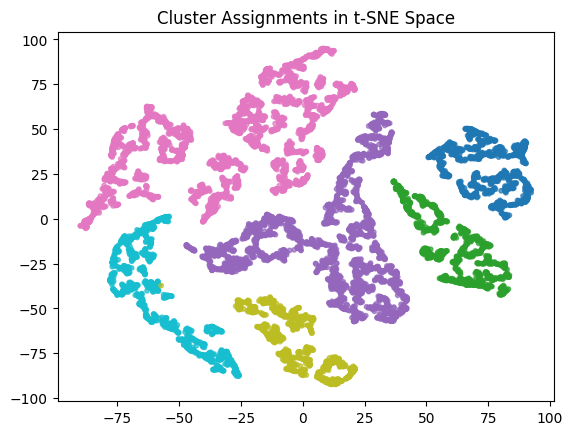

In [13]:
#  Reduce dimensions to 2D using t-SNE for visualization - takes 20 seconds
tsne = TSNE(n_components=2, random_state=1)
X_2d = tsne.fit_transform(X_red)
# Plot cluster Assignments
scatter1 = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='tab10', s=10, alpha=0.7)
plt.title("Cluster Assignments in t-SNE Space")
plt.show()

This only looks like 6 clusters, though! We can check the cluster counts: 

In [14]:
image_counts = [0 for _ in range(10)] 
for j in range(10):
    for i in range(len(labels)):
        if labels[i] == j:  # Only collect images that belong to the current cluster
            image_counts[j]+=1
print(image_counts)

[1027, 1038, 2741, 3056, 909, 1229, 0, 0, 0, 0]


In [15]:
n_images = X.shape[0]

# Convert data to numpy image pixel-by-pixel representation
X_images = X.reshape(n_images, 28, 28)

In [ ]:
image_cluster = [[] for _ in range(10)] 
# Collect all images that belong to each cluster. j ranges over the cluster labels (0-9) 
img_max = 300
for j in range(10):
    for i in range(img_max):
        if labels[i] == j:  # Only collect images that belong to the current cluster
            image_cluster[j].append(X_images[i, :])
def plot_images(labels, X_images, n_clusters):
    image_cluster = [[] for _ in range(n_clusters)] 
    # Collect all images that belong to each cluster. j ranges over the cluster labels (0-9) 
    for j in range(n_clusters):
        for i in range(img_max):
            if labels[i] == j:  # Only collect images that belong to the current cluster
                image_cluster[j].append(X_images[i, :])
            if len(image_cluster[j]) >= 10:  # Limit to 10 images per cluster
                break
            
    for n in range(len(image_cluster)):
        k = len(image_cluster[n])
        if k!= 0:
            fig, axes = plt.subplots(1, k, figsize=(1 * k, 1), squeeze=False)
            for i, ax in enumerate(axes[0]):
                ax.imshow(image_cluster[n][i], cmap=plt.cm.gray)
                ax.set_title(f"Cluster{n}")
                ax.axis("off")
            plt.show()
plot_images(labels, X_images, 10)

Calculate the accuracy after manually assigning the cluster labels. 

# Analysis and Conclusions 
## Write your answers here
What happens to accuracy when you increase k in the k-means approach? 


Compare the accuracy of the two different clustering algorithms (for a given value of k). 